Business Statement:
Business Problem is that universities want to identify students who are at risk of dropping out. Using demographic, socioeconomic, enrollment, and academic information, I built a multiclass classification model to predict whether a student is likely to Dropout, remain Enrolled, or Graduate. This prediction can help the institution take early intervention measures and improve student retention and graduation rates.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (train_test_split, StratifiedKFold,cross_val_score)
from sklearn.preprocessing import (LabelEncoder,StandardScaler)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,classification_report,confusion_matrix,ConfusionMatrixDisplay,f1_score,precision_score,recall_score)

In [2]:
df = pd.read_csv(r"Downloads/classification_datasets/dataset.csv")
df

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1,1,6,15,1,1,1,1,1,6,...,0,6,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1,1,2,15,1,1,19,1,1,10,...,0,6,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1,1,1,12,1,1,1,22,27,10,...,0,8,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1,1,1,9,1,1,1,22,27,8,...,0,5,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                      

In [4]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,6.886980,1.727848,9.899186,0.890823,2.531420,1.254521,12.322107,16.455244,7.317812,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,5.298964,1.313793,4.331792,0.311897,3.963707,1.748447,9.026251,11.044800,3.997828,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,6.000000,1.000000,1.000000,1.000000,2.000000,3.000000,5.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,8.000000,1.000000,10.000000,1.000000,1.000000,1.000000,13.000000,14.000000,6.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,12.000000,2.000000,13.000000,1.000000,1.000000,1.000000,22.000000,27.000000,10.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,18.000000,9.000000,17.000000,1.000000,17.000000,21.000000,29.000000,34.000000,32.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [5]:
df.columns.tolist()

['Marital status',
 'Application mode',
 'Application order',
 'Course',
 'Daytime/evening attendance',
 'Previous qualification',
 'Nacionality',
 "Mother's qualification",
 "Father's qualification",
 "Mother's occupation",
 "Father's occupation",
 'Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'Age at enrollment',
 'International',
 'Curricular units 1st sem (credited)',
 'Curricular units 1st sem (enrolled)',
 'Curricular units 1st sem (evaluations)',
 'Curricular units 1st sem (approved)',
 'Curricular units 1st sem (grade)',
 'Curricular units 1st sem (without evaluations)',
 'Curricular units 2nd sem (credited)',
 'Curricular units 2nd sem (enrolled)',
 'Curricular units 2nd sem (evaluations)',
 'Curricular units 2nd sem (approved)',
 'Curricular units 2nd sem (grade)',
 'Curricular units 2nd sem (without evaluations)',
 'Unemployment rate',
 'Inflation rate',
 'GDP',
 'Target']

In [6]:
df.isnull().sum()

Marital status                                    0
Application mode                                  0
Application order                                 0
Course                                            0
Daytime/evening attendance                        0
Previous qualification                            0
Nacionality                                       0
Mother's qualification                            0
Father's qualification                            0
Mother's occupation                               0
Father's occupation                               0
Displaced                                         0
Educational special needs                         0
Debtor                                            0
Tuition fees up to date                           0
Gender                                            0
Scholarship holder                                0
Age at enrollment                                 0
International                                     0
Curricular u

In [7]:
df.duplicated().sum()

0

In [8]:
df.shape

(4424, 35)

In [9]:
print(df.dtypes)

Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance                          int64
Previous qualification                              int64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender                                              int64
Scholarship holder                                  int64
Age at enrollm

In [10]:
df["Target"].value_counts

<bound method IndexOpsMixin.value_counts of 0        Dropout
1       Graduate
2        Dropout
3       Graduate
4       Graduate
          ...   
4419    Graduate
4420     Dropout
4421     Dropout
4422    Graduate
4423    Graduate
Name: Target, Length: 4424, dtype: object>

In [11]:
df["Target"].unique()

array(['Dropout', 'Graduate', 'Enrolled'], dtype=object)

In [12]:
df['Target'].value_counts(normalize=True) * 100

Target
Graduate    49.932188
Dropout     32.120253
Enrolled    17.947559
Name: proportion, dtype: float64

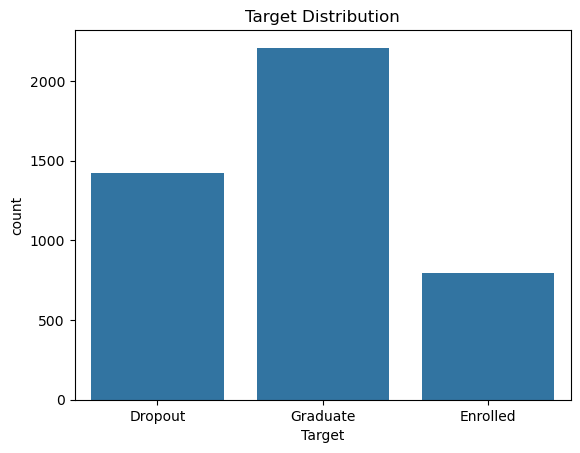

In [13]:
sns.countplot(data=df, x='Target')
plt.title('Target Distribution')
plt.show()

In [14]:
num_cols = [
    'Age at enrollment',
    'Curricular units 1st sem (credited)',
    'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)',
    'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)',
    'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)',
    'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)',
    'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)',
    'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate',
    'Inflation rate',
    'GDP'
]

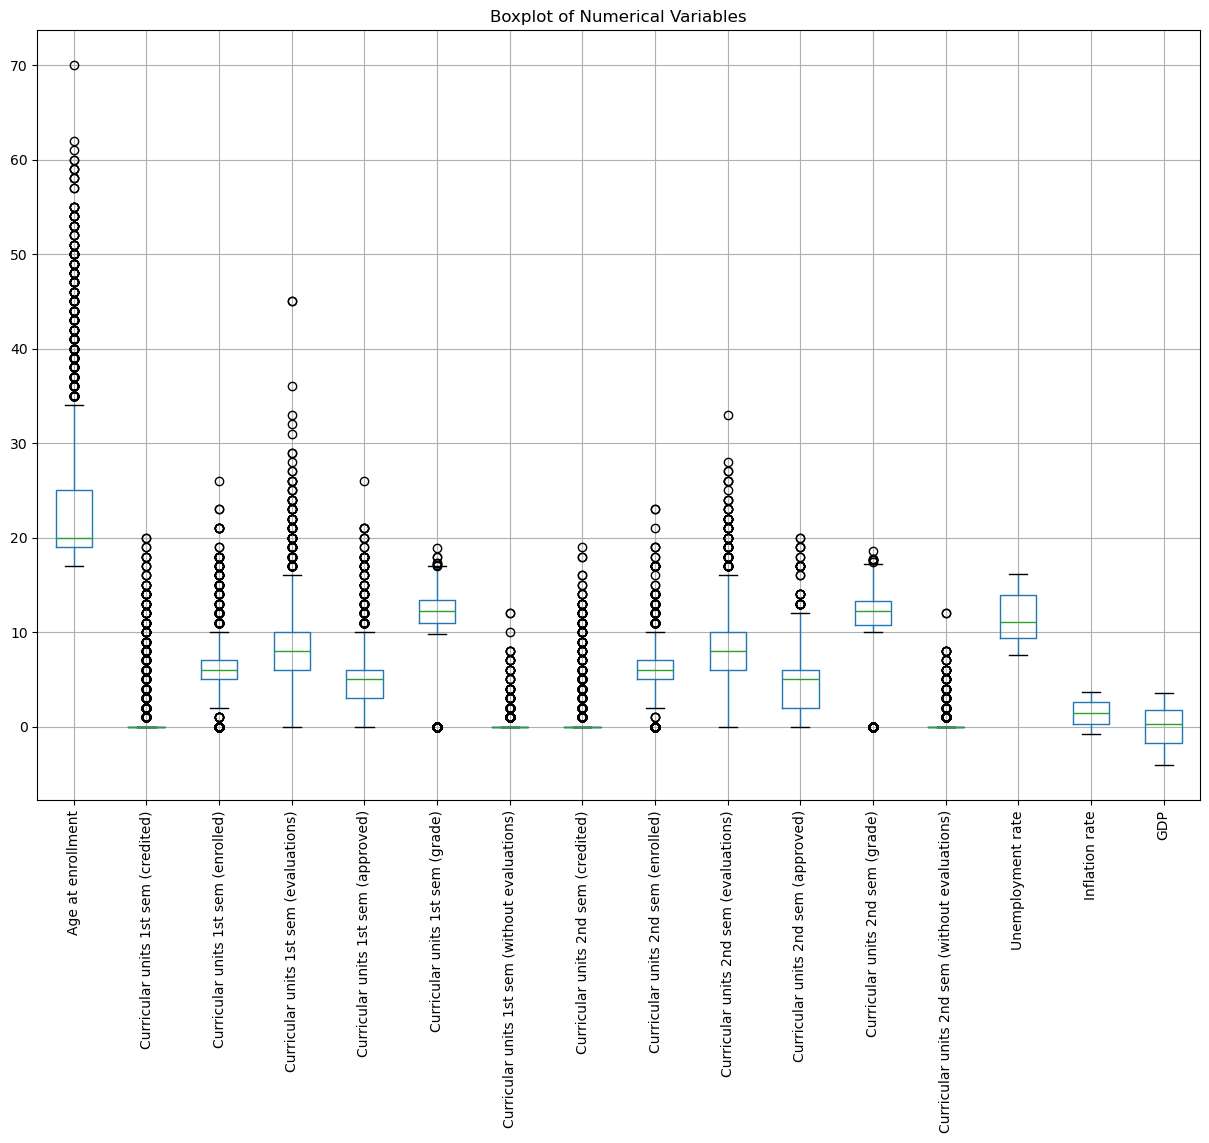

In [15]:
plt.figure(figsize=(15, 10))

df[num_cols].boxplot()

plt.xticks(rotation=90)
plt.title("Boxplot of Numerical Variables")
plt.show()

In [16]:
for col in num_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print("Column:", col)
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))
    print("-" * 60)

Column: Age at enrollment
Q1: 19.0
Q3: 25.0
IQR: 6.0
Lower Bound: 10.0
Upper Bound: 34.0
Number of Outliers: 441
------------------------------------------------------------
Column: Curricular units 1st sem (credited)
Q1: 0.0
Q3: 0.0
IQR: 0.0
Lower Bound: 0.0
Upper Bound: 0.0
Number of Outliers: 577
------------------------------------------------------------
Column: Curricular units 1st sem (enrolled)
Q1: 5.0
Q3: 7.0
IQR: 2.0
Lower Bound: 2.0
Upper Bound: 10.0
Number of Outliers: 424
------------------------------------------------------------
Column: Curricular units 1st sem (evaluations)
Q1: 6.0
Q3: 10.0
IQR: 4.0
Lower Bound: 0.0
Upper Bound: 16.0
Number of Outliers: 158
------------------------------------------------------------
Column: Curricular units 1st sem (approved)
Q1: 3.0
Q3: 6.0
IQR: 3.0
Lower Bound: -1.5
Upper Bound: 10.5
Number of Outliers: 180
------------------------------------------------------------
Column: Curricular units 1st sem (grade)
Q1: 11.0
Q3: 13.4
IQR: 2.

In [17]:
df[num_cols].describe()


,Age at enrollment,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,23.265145,0.709991,6.270570,8.299051,4.706600,10.640822,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,7.587816,2.360507,2.480178,4.179106,3.094238,4.843663,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,19.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,20.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,25.000000,0.000000,7.000000,10.000000,6.000000,13.400000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,70.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


In [18]:
data = df.copy()

In [19]:
target_col = "Target"

In [20]:
X = data.drop(columns=[target_col])
y = data[target_col]

In [21]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state=42)

In [22]:
from sklearn.linear_model import LogisticRegression
log_ = LogisticRegression()
log_.fit(X_train,y_train)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [24]:
ypred_train = log_.predict(X_train)
ypred_test = log_.predict(X_test)

In [25]:
from sklearn.metrics import accuracy_score

print("Training Accuracy:",accuracy_score(y_train,ypred_train))
print("Testing Accuracy:",accuracy_score(y_test,ypred_test))

Training Accuracy: 0.7810115851935575
Testing Accuracy: 0.7559322033898305


In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log = LogisticRegression(max_iter=2000)

log.fit(X_train_scaled, y_train)

ypred_train = log.predict(X_train_scaled)
ypred_test = log.predict(X_test_scaled)

In [27]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'solver': ['lbfgs', 'liblinear'],
    'class_weight': [None, 'balanced']
}

grid = GridSearchCV(
    LogisticRegression(max_iter=2000),
    param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1
)

grid.fit(X_train_scaled, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

Best Parameters: {'C': 1, 'class_weight': 'balanced', 'solver': 'liblinear'}
Best CV Score: 0.7598144981442699


In [28]:
best_log = grid.best_estimator_

ypred_test = best_log.predict(X_test_scaled)

In [29]:
accuracy_score(y_test, ypred_test)

0.7468926553672316

In [30]:
precision_score(y_test,ypred_test,average='weighted')

0.7342932259588706

In [31]:
recall_score(y_test,ypred_test,average='weighted')

0.7468926553672316

In [32]:
f1_score(y_test,ypred_test,average='weighted')

0.7375440360758495

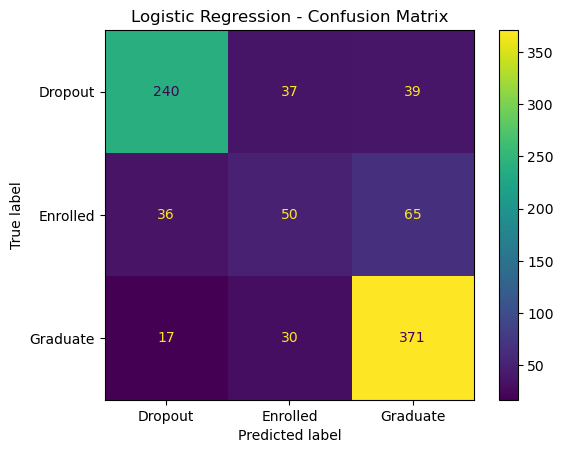

In [33]:
ConfusionMatrixDisplay.from_predictions(y_test,ypred_test)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [34]:
y_prob = best_log.predict_proba(X_test_scaled)

In [35]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    y_test,
    y_prob,
    multi_class='ovr',
    average='weighted'
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8849457219165857


In [36]:
LogisticRegression(max_iter=2000,class_weight=None)

LogisticRegression(max_iter=2000)

In [37]:
LogisticRegression(max_iter=2000,class_weight='balanced')

LogisticRegression(class_weight='balanced', max_iter=2000)

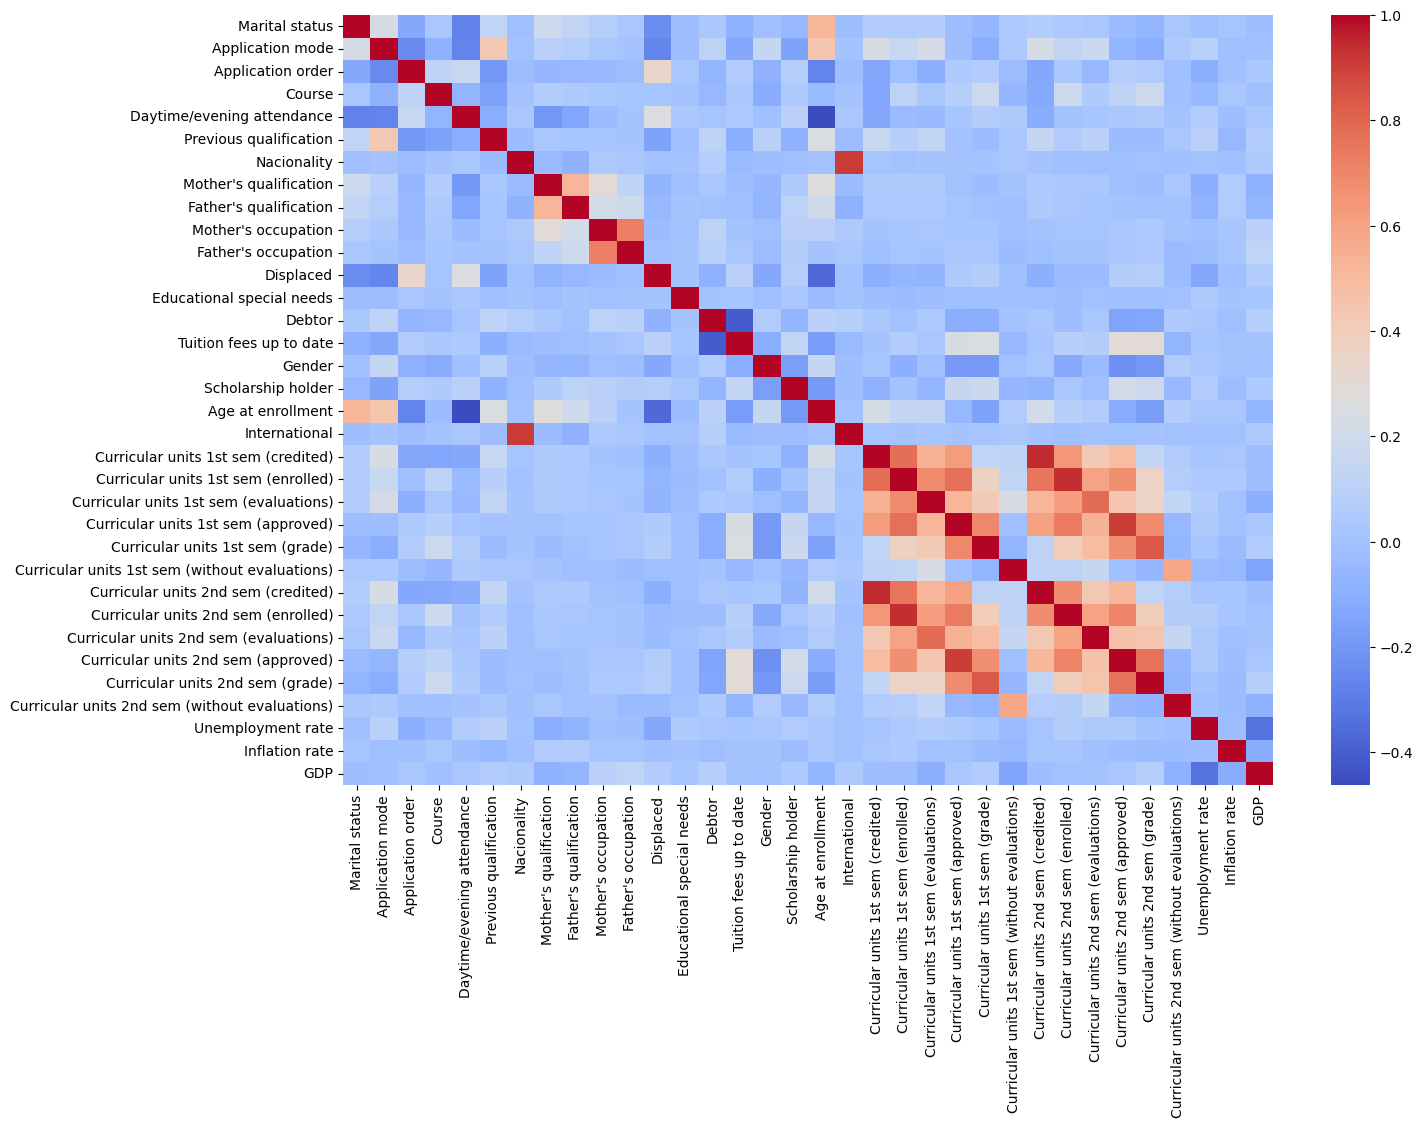

In [38]:
corr = X.corr()

plt.figure(figsize=(15,10))
sns.heatmap(corr, cmap='coolwarm')
plt.show()

In [39]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()

vif_data["Feature"] = X.columns

vif_data["VIF"] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

vif_data.sort_values("VIF", ascending=False)

,Feature,VIF
20,Curricular units 1st sem (enrolled),172.380705
26,Curricular units 2nd sem (enrolled),153.388956
22,Curricular units 1st sem (approved),42.141554
28,Curricular units 2nd sem (approved),33.025656
23,Curricular units 1st sem (grade),28.782252
29,Curricular units 2nd sem (grade),26.823782
31,Unemployment rate,19.855342
21,Curricular units 1st sem (evaluations),19.683509
17,Age at enrollment,19.109473
27,Curricular units 2nd sem (evaluations),17.429092


In [40]:
coef = pd.DataFrame(best_log.coef_,columns=X.columns)
coef

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
0,-0.081739,-0.005964,0.084960,0.390232,0.055759,-0.033960,0.354863,0.199374,-0.027612,-0.299688,...,-0.006375,0.443714,1.064562,-0.107812,-1.895164,-0.346007,-0.113192,0.256021,0.056212,0.028091
1,0.010717,0.119459,-0.011554,-0.044874,0.013323,-0.179257,-0.047475,-0.182468,-0.044896,0.134251,...,-0.064371,-0.006378,-0.321513,0.677357,-0.303978,0.609465,-0.045485,-0.142873,-0.000271,-0.046420
2,0.153539,-0.088066,-0.052889,-0.274532,-0.016962,0.172722,-0.097365,0.084351,0.085894,0.058811,...,-0.007819,-0.027615,-1.503960,-0.467678,2.577699,0.609348,0.194063,-0.100884,0.004408,-0.015781


In [41]:
cross_val_score(log, X, y, cv=5)

array([0.78079096, 0.76384181, 0.78644068, 0.76723164, 0.74434389])

In [42]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    best_log,
    X_train_scaled,
    y_train,
    cv=skf,
    scoring='f1_weighted'
)

print("CV Scores:", scores)
print("Mean CV F1:", scores.mean())

CV Scores: [0.75264425 0.7612237  0.77176733 0.75018192 0.76468695]
Mean CV F1: 0.7601008298601549


In [43]:
from sklearn.metrics import classification_report

print(classification_report(y_test, ypred_test))

              precision    recall  f1-score   support

     Dropout       0.82      0.76      0.79       316
    Enrolled       0.43      0.33      0.37       151
    Graduate       0.78      0.89      0.83       418

    accuracy                           0.75       885
   macro avg       0.68      0.66      0.66       885
weighted avg       0.73      0.75      0.74       885



# Conclusion

The classification model can help the university identify students who are at higher risk of dropping out. The model's performance should be evaluated not only by overall accuracy but also by recall for the Dropout class and performance on the Enrolled class. Students predicted as Dropout could be prioritized for academic counselling, financial support, mentoring, or other retention interventions.